# ShelfWatch 01: fine-tune a YOLO detector on SKU-110K and export it to ONNX

**Goal:** a small detector that finds every product on a shelf photo, saved as one `.onnx` file for the Streamlit app.

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Then run the cells top to bottom.

| Step | What happens | Roughly how long |
|---|---|---|
| 0 | Settings, install, connect Google Drive | 2 min |
| 1 | Download SKU-110K (about 13.6 GB) and look at it | 15–30 min, once per session |
| 2 | Smoke test: 1 short epoch to prove memory and paths work | 5 min |
| 3 | Real training on a subset | the longest step; saved to Drive |
| 4 | Test-set evaluation | 5–10 min |
| 5 | Export to ONNX and check it like the app will use it | 5 min |

Training results are written to **Google Drive**, so a Colab disconnect does not lose them (see the resume cell in Step 3).

## Step 0 · Settings, install, Google Drive

In [20]:
# Every choice you might change lives here, so experiments are easy to repeat and report.
MODEL    = "yolo11n.pt"   # the brief's model. Alternative: "yolo26n.pt" (newer; Ultralytics' current default)
IMGSZ    = 960            # shelf products are small; 640 loses detail, 1280 is slower
FRACTION = 0.30           # share of the 8,219 training images to use (0.30 ≈ 2,466). The "subset".
EPOCHS   = 50
BATCH    = 8              # if Step 2 runs out of GPU memory, use 4
MAX_DET  = 1000           # shelves can hold more than the default 300 boxes
SEED     = 0
RUN_DIR  = "/content/drive/MyDrive/shelfwatch/runs"   # on Drive so results survive a disconnect

In [21]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
%pip install -q ultralytics onnxruntime

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [22]:
# Drive keeps results safe if Colab disconnects. Only results go there (a few MB), never the dataset.
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:   # e.g. some VS Code + Colab setups cannot mount Drive
    RUN_DIR = "/content/runs"
    print(f"Drive not mounted ({e}). Saving to {RUN_DIR}: download results before the session ends.")
os.makedirs(RUN_DIR, exist_ok=True); print("results go to", RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
results go to /content/drive/MyDrive/shelfwatch/runs


## Step 1 · Download SKU-110K and look at it

`SKU-110K.yaml` ships with Ultralytics. The first time it is used, it downloads the original archive and converts the CSV
annotations to YOLO label files (`0 x_centre y_centre width height`, as fractions of the image). There is one class, `object`.

**Licence:** SKU-110K (Goldman et al., CVPR 2019) is for research use. Do not commit the images to GitHub.

In [23]:
from ultralytics.data.utils import check_det_dataset
data = check_det_dataset("SKU-110K.yaml")       # downloads and converts on first run
print({k: data[k] for k in ("path", "train", "val", "test", "names")})

{'path': PosixPath('/content/datasets/SKU-110K'), 'train': '/content/datasets/SKU-110K/train.txt', 'val': '/content/datasets/SKU-110K/val.txt', 'test': '/content/datasets/SKU-110K/test.txt', 'names': {0: 'object'}}


In [24]:
# How many boxes does a shelf photo have? This is why MAX_DET matters.
import glob, numpy as np
from pathlib import Path
root = Path(data["path"])

# SKU-110K keeps every image in one images/ folder; train.txt, val.txt, test.txt list which image is in which split.
def split_images(split):
    return [str(root / line.strip()) for line in open(root / f"{split}.txt") if line.strip()]
def label_path(img_path):
    return root / "labels" / (Path(img_path).stem + ".txt")

counts = {}
for split in ("train", "val", "test"):
    imgs = split_images(split)
    assert imgs, f"{split}.txt lists no images: did the download finish?"
    n = np.array([sum(1 for _ in open(label_path(p))) if label_path(p).exists() else 0 for p in imgs])
    counts[split] = n
    print(f"{split:5s}: {len(imgs):5d} images | boxes per image: median {np.median(n):.0f}, max {n.max()} | images without labels: {(n == 0).sum()}")
print("images with more than 300 boxes:", int((counts['test'] > 300).sum()), "of", len(counts['test']), "test images")

train:  8219 images | boxes per image: median 138, max 576 | images without labels: 0
val  :   588 images | boxes per image: median 139, max 718 | images without labels: 0
test :  2936 images | boxes per image: median 137, max 533 | images without labels: 0
images with more than 300 boxes: 30 of 2936 test images


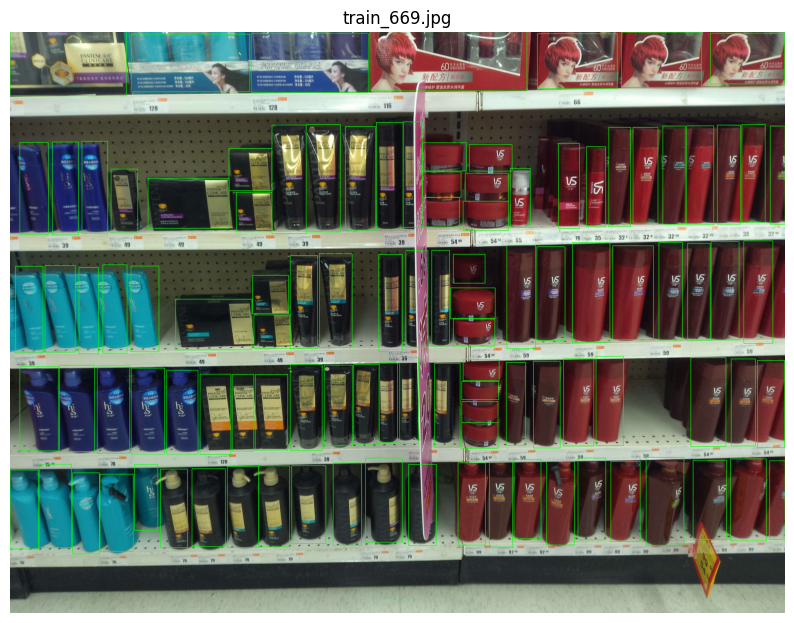

In [25]:
# Draw the labelled boxes on one training image.
import cv2, random, matplotlib.pyplot as plt
random.seed(SEED)
img_path = random.choice(split_images("train"))
img = cv2.imread(img_path); H, W = img.shape[:2]
for line in open(label_path(img_path)):
    _, cx, cy, w, h = map(float, line.split())
    x1, y1, x2, y2 = int((cx - w/2) * W), int((cy - h/2) * H), int((cx + w/2) * W), int((cy + h/2) * H)
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
plt.figure(figsize=(10, 8)); plt.imshow(img[:, :, ::-1]); plt.axis("off"); plt.title(Path(img_path).name); plt.show()

## Step 2 · Smoke test (1 short epoch)

Uses 2 % of the training images for one epoch. It proves the GPU has enough memory at this `IMGSZ` and `BATCH`, and that
saving to Drive works, **before** you spend an hour on the real run. If it crashes with "CUDA out of memory", set `BATCH = 4`.

In [26]:
from ultralytics import YOLO
YOLO(MODEL).train(data="SKU-110K.yaml", epochs=1, fraction=0.02, imgsz=IMGSZ, batch=BATCH,
                  max_det=MAX_DET, project=RUN_DIR, name="smoke", exist_ok=True, seed=SEED, plots=False)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=SKU-110K.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.02, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a1ad5d4de50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## Step 3 · Real training on the subset

- **Transfer learning:** we start from COCO-pretrained weights, so the model already knows edges and shapes and only has
  to learn what "a product on a shelf" looks like.
- `fraction=FRACTION` is the subset: Ultralytics trains on that share of the training images. Validation uses all 588 val images.
- `patience=10` stops early once validation mAP has not improved for 10 epochs, saving free GPU time.
- After every epoch, `last.pt` and `best.pt` are saved to Drive.

In [27]:
model = YOLO(MODEL)
model.train(data="SKU-110K.yaml", epochs=EPOCHS, fraction=FRACTION, imgsz=IMGSZ, batch=BATCH,
            patience=10, max_det=MAX_DET, project=RUN_DIR, name="train", exist_ok=True, seed=SEED)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=SKU-110K.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.3, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a1b10bf1010>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [28]:
# Only if Colab disconnected mid-training: re-run Step 0 and Step 1's download cell, then this cell.
# model = YOLO(f"{RUN_DIR}/train/weights/last.pt")
# model.train(resume=True)

## Step 4 · Evaluate on the held-out test set

The test images were never used for training or for choosing when to stop, so this is the honest number for the report.
**mAP@0.5** = how well boxes match the real products when "a match" means at least 50 % overlap.

In [29]:
best = YOLO(f"{RUN_DIR}/train/weights/best.pt")
m = best.val(data="SKU-110K.yaml", split="test", imgsz=IMGSZ, batch=BATCH, max_det=MAX_DET,
             project=RUN_DIR, name="test", exist_ok=True)
print(f"test mAP@0.5 = {m.box.map50:.3f} | mAP@0.5:0.95 = {m.box.map:.3f} | precision = {m.box.mp:.3f} | recall = {m.box.mr:.3f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 138.4±63.0 MB/s, size: 1300.4 KB)
val: Scanning /content/datasets/SKU-110K/labels... 2935 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 2936/2936 76.4it/s 38.4s0.1sss
val: /content/datasets/SKU-110K/images/test_1029.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1035.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1059.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1086.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1090.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1102.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_112.jpg: corrupt JPEG restored and saved
val: /con

## Step 5 · Export to ONNX and check it the way the app will use it

We export the **raw** output: shape `(1, 5, N)` = 4 box numbers + 1 "product" score for each of N candidate boxes.
The app then applies a confidence threshold and NMS itself, exactly like `yolo_utils.Yolo11` from the class lab.
(For `yolo26n.pt` this is also the default export; its "NMS-free" option is capped at 300 boxes, too few for shelves.)

In [30]:
onnx_path = best.export(format="onnx", imgsz=IMGSZ)
print(onnx_path, f"{os.path.getsize(onnx_path) / 1e6:.1f} MB")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 14.7 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/shelfwatch/runs/train/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 5, 18900) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 396ms
Prepared 3 packages in 227ms
Installed 3 packages in 39ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99.

In [31]:
# Run the ONNX file with onnxruntime on CPU only (like Streamlit Cloud), decode it by hand, and compare with PyTorch.
import time, onnxruntime as ort
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
inp = sess.get_inputs()[0]
print("input:", inp.name, inp.shape, "| output:", sess.get_outputs()[0].shape)

def letterbox(bgr, size):
    h, w = bgr.shape[:2]; s = size / max(h, w); nw, nh = round(w * s), round(h * s)
    out = np.full((size, size, 3), 114, np.uint8); px, py = (size - nw) // 2, (size - nh) // 2
    out[py:py + nh, px:px + nw] = cv2.resize(bgr, (nw, nh)); return out, s, px, py

def onnx_detect(bgr, conf=0.25, iou=0.7):
    im, s, px, py = letterbox(bgr, IMGSZ)
    x = cv2.cvtColor(im, cv2.COLOR_BGR2RGB).astype(np.float32).transpose(2, 0, 1)[None] / 255.0
    out = sess.run(None, {inp.name: x})[0][0]               # (5, N): cx, cy, w, h, score
    assert out.shape[0] == 5, f"expected 5 rows for 1 class, got {out.shape}"
    keep = out[4] >= conf
    cx, cy, w, h, sc = out[:, keep]
    boxes = np.stack([(cx - w/2 - px) / s, (cy - h/2 - py) / s, w / s, h / s], 1)   # x, y, w, h in original pixels
    idx = cv2.dnn.NMSBoxes(boxes.tolist(), sc.tolist(), conf, iou, top_k=MAX_DET)
    return boxes[np.array(idx).flatten()] if len(idx) else boxes[:0]

test_imgs = split_images("test")[:10]
times = []
for p in test_imgs:
    bgr = cv2.imread(p); t0 = time.time(); b = onnx_detect(bgr); times.append(time.time() - t0)
    n_pt = len(best.predict(p, imgsz=IMGSZ, conf=0.25, iou=0.7, max_det=MAX_DET, verbose=False)[0].boxes)
    print(f"{Path(p).name}: ONNX {len(b):4d} boxes | PyTorch {n_pt:4d} boxes")
print(f"ONNX on CPU: {np.mean(times):.2f} s per image (Colab CPU; re-measure on Streamlit Cloud)")

input: images [1, 3, 960, 960] | output: [1, 5, 18900]
test_0.jpg: ONNX  123 boxes | PyTorch  141 boxes
test_1.jpg: ONNX  122 boxes | PyTorch  144 boxes
test_10.jpg: ONNX  122 boxes | PyTorch  145 boxes
test_100.jpg: ONNX  129 boxes | PyTorch  170 boxes
test_1000.jpg: ONNX  120 boxes | PyTorch  148 boxes
test_1001.jpg: ONNX  133 boxes | PyTorch  187 boxes
test_1002.jpg: ONNX  128 boxes | PyTorch  205 boxes
test_1003.jpg: ONNX  163 boxes | PyTorch  167 boxes
test_1004.jpg: ONNX  133 boxes | PyTorch  158 boxes
test_1005.jpg: ONNX  124 boxes | PyTorch  158 boxes
ONNX on CPU: 0.28 s per image (Colab CPU; re-measure on Streamlit Cloud)


In [32]:
# Save the model next to the training run on Drive, and download a copy for shelfwatch/models/.
import shutil
final = f"{RUN_DIR}/shelf_{Path(MODEL).stem}_{IMGSZ}.onnx"
shutil.copy(onnx_path, final); print("saved to", final)
try:
    from google.colab import files
    files.download(final)          # works in the Colab web page
except Exception as e:             # in VS Code: take the file from Google Drive instead
    print(f"Browser download not available ({e}). Get the file from Google Drive: {final}")

saved to /content/drive/MyDrive/shelfwatch/runs/shelf_yolo11n_960.onnx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What to copy into your report

- Settings from Step 0 (model, image size, subset fraction, epochs, batch, seed).
- The training curves: `RUN_DIR/train/results.png` (loss falling, mAP rising then flat).
- Test mAP@0.5, mAP@0.5:0.95, precision and recall from Step 4.
- ONNX file size, and whether ONNX and PyTorch box counts agree (Step 5).

**Next:** copy the downloaded `.onnx` file into `shelfwatch/models/`.